Гипотезы

1. Запах - самый информативный признак для определения ядовитости гриба
2. Размер пластинок и цвет спор сильно связаны с ядовитостью гриба
3. Логистическая регрессия сможет получить F1 выше 0.95
4. Random Forest покажет качество не хуже логистической регрессии
5. Подбор гиперпараметров улучшит качество логистической регрессии
6. Запах окажется самым важным признаком и для обученной модели

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("mushrooms.csv", na_values='?')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [2]:
df.shape

(8124, 23)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                5644 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [4]:
miss = df.isna().sum()
miss[miss > 0]

stalk-root    2480
dtype: int64

очень много пропусков по ножкам грибов, удалять строчки нельзя - потеряем много иннформации

In [5]:
X = df.drop(columns='class')
y = df['class'].map({'e': 0, 'p': 1})

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
class_counts = y_train.value_counts().sort_index()
class_counts

class
0    3366
1    3133
Name: count, dtype: int64

In [8]:
(y_train.value_counts(normalize=True) * 100).round(2)

class
0    51.79
1    48.21
Name: proportion, dtype: float64

Дисбаланса нет

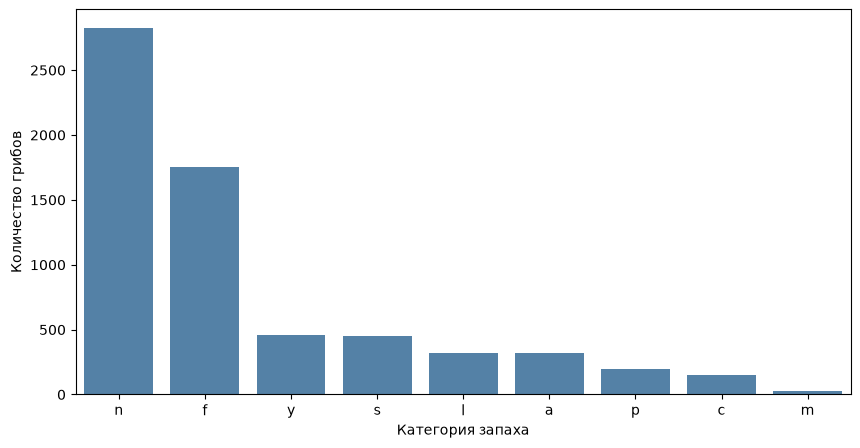

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=X_train,
    x="odor",
    order=X_train["odor"].value_counts().index,
    color="steelblue"
)

plt.xlabel("Категория запаха")
plt.ylabel("Количество грибов")
plt.show()

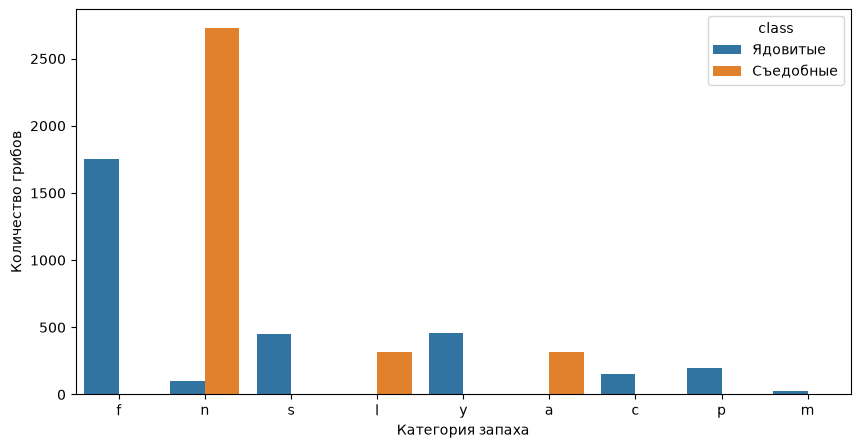

In [10]:
train_df = X_train.copy()
train_df["class"] = y_train.map({
    0: "Съедобные",
    1: "Ядовитые"
})

plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="odor",
    hue="class")

plt.xlabel("Категория запаха")
plt.ylabel("Количество грибов")
plt.show()

Запах сильно связан с ядовитостью гриба  


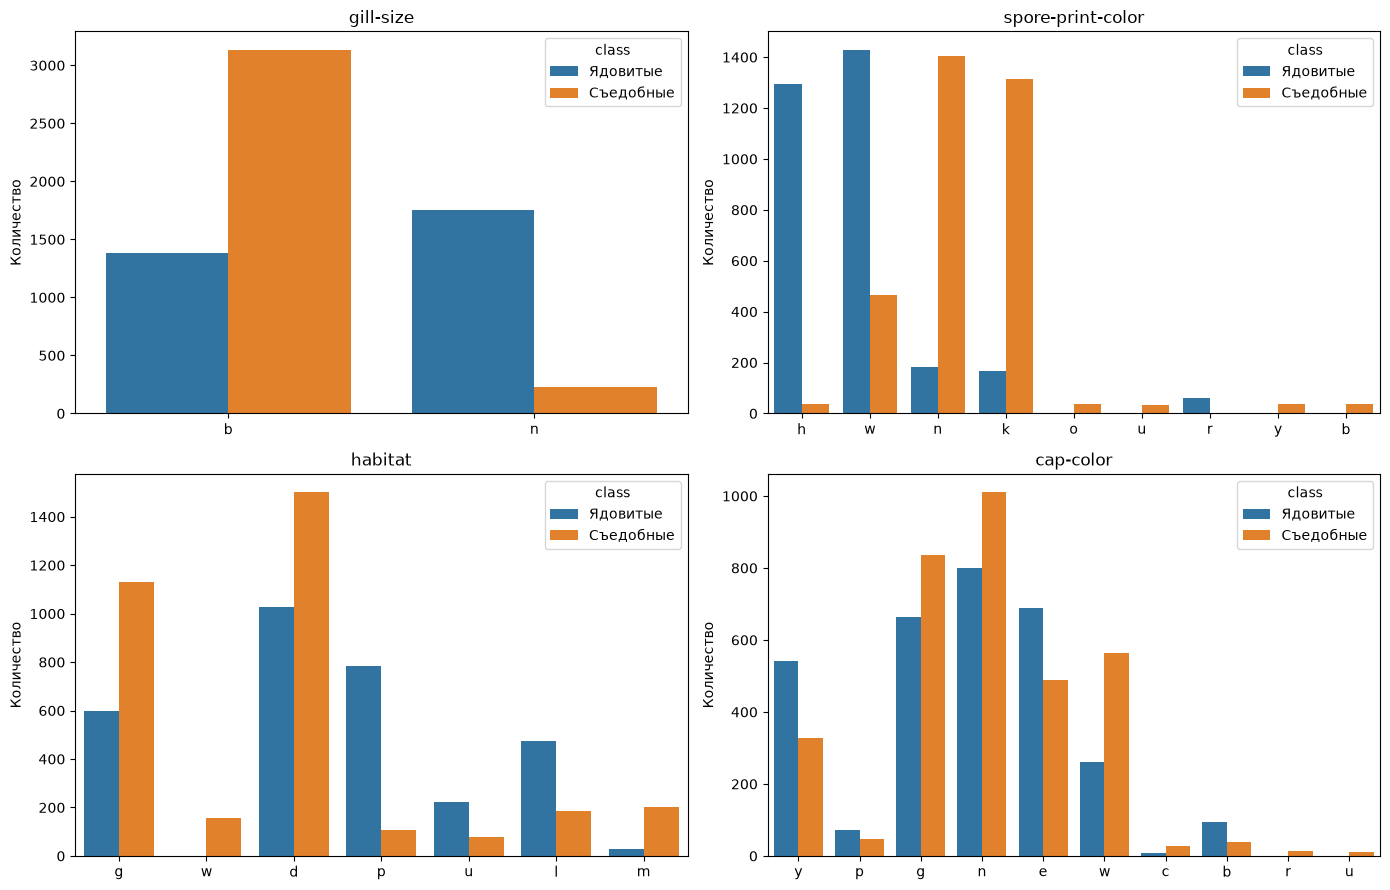

In [11]:
features = ["gill-size", "spore-print-color", "habitat", "cap-color"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(features, axes.flat):
    sns.countplot(data=train_df, x=feature, hue="class", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Количество")

plt.tight_layout()
plt.show()

Размер пластинок и цвет спор тоже информативны  
Гипотеза 2 подтвердилась

In [12]:
unique_counts = X_train.nunique(dropna=False)
constant_features = unique_counts[unique_counts == 1].index.tolist()

print(constant_features)
print(X_train.duplicated().sum())

print(X_train.isna().sum()[X_train.isna().sum() > 0])

['veil-type']
0
stalk-root    1968
dtype: int64


Постоянный признак не помогает различать классы

In [13]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x.fillna("missing"), y)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

association = pd.Series({
    column: cramers_v(X_train[column], y_train)
    for column in X_train.columns
}).sort_values(ascending=False)

association.round(3)

odor                        0.971
spore-print-color           0.756
gill-color                  0.680
ring-type                   0.604
stalk-surface-above-ring    0.592
stalk-surface-below-ring    0.576
gill-size                   0.532
stalk-color-above-ring      0.527
stalk-color-below-ring      0.518
bruises                     0.503
population                  0.489
habitat                     0.435
stalk-root                  0.410
gill-spacing                0.349
cap-shape                   0.244
cap-color                   0.215
ring-number                 0.213
cap-surface                 0.190
veil-color                  0.150
gill-attachment             0.129
stalk-shape                 0.104
veil-type                   0.000
dtype: float64

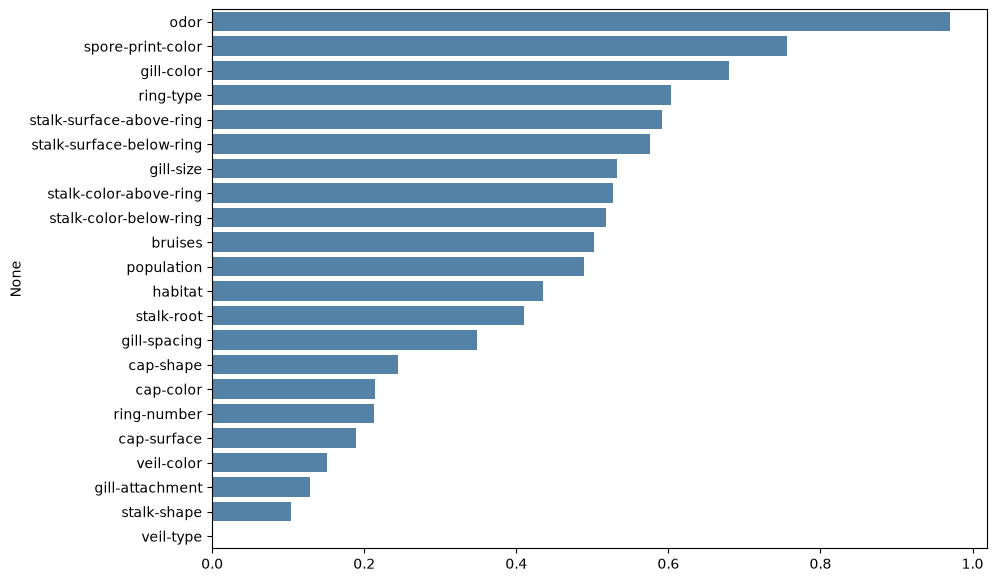

In [14]:
plt.figure(figsize=(10, 7))
sns.barplot(x=association.values, y=association.index, color="steelblue")
plt.show()

Запах - самый информативный признак, гипотеза 1 подтвердилась

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, chi2


def make_pipeline(model, encoding="onehot", k=None):
    if encoding == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore")
    elif encoding == "ordinal":
        encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1
        )

    steps = [
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("encoder", encoder),
    ]

    if k is not None:
        steps.append(("selection", SelectKBest(score_func=chi2, k=k)))

    steps.append(("model", model))
    return Pipeline(steps)

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.metrics import make_scorer, precision_score, recall_score

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=1
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metrics = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": "f1",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
}

In [17]:
results = []

for name, model in models.items():
    pipeline = make_pipeline(model)
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=metrics, n_jobs=2
    )
    results.append({
        "Модель": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "F1 std": scores["test_f1"].std(),
        "F1 macro": scores["test_f1_macro"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
results_df.round(4)

,Модель,Accuracy,Precision,Recall,F1,F1 std,F1 macro,ROC-AUC
3,Random Forest,1.0000,1.0,1.0000,1.0000,0.0000,1.0000,1.0000
2,Decision Tree,0.9997,1.0,0.9994,0.9997,0.0006,0.9997,0.9997
1,Logistic Regression,0.9994,1.0,0.9987,0.9994,0.0013,0.9994,1.0000
0,Dummy,0.5179,0.0,0.0000,0.0000,0.0000,0.3412,0.5000


Все модели показали почти идеальное качество

Гипотезы 3 и 4 подтвердились

In [18]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10, 100]
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 10, None],
        "model__min_samples_leaf": [1, 5]
    },
    "Random Forest": {
        "model__n_estimators": [100, 150],
        "model__max_depth": [10, None]
    },
}

searches = {}
tuning_rows = []

for name, grid in param_grids.items():
    search = GridSearchCV(
        estimator=make_pipeline(models[name]),
        param_grid=grid,
        scoring="f1",
        cv=cv,
        n_jobs=2,
        refit=True
    )
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({
        "Модель": name,
        "CV F1": search.best_score_,
        "Лучшие параметры": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("CV F1", ascending=False)
tuning_df

,Модель,CV F1,Лучшие параметры
0,Logistic Regression,1.000000,{'model__C': 100}
2,Random Forest,1.000000,"{'model__max_depth': 10, 'model__n_estimators'..."
1,Decision Tree,0.999681,"{'model__max_depth': 5, 'model__min_samples_le..."


Гипотеза 5 подтвердилась

In [19]:
best_name = tuning_df.iloc[0]["Модель"]
best_search = searches[best_name]
best_model = best_search.best_estimator_

print(best_name)
print(round(best_search.best_score_, 4))
print(best_search.best_params_)

Logistic Regression
1.0
{'model__C': 100}


Выбрали логистическую регрессию с C = 100, потому что легче других, хотя метрики такие же

In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F1 macro": f1_score(y_test, y_pred, average="macro"),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
})

test_metrics.round(4)

Accuracy     1.0
Precision    1.0
Recall       1.0
F1           1.0
F1 macro     1.0
ROC-AUC      1.0
dtype: float64

In [21]:
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Съедобный", "Ядовитый"],
    zero_division=0
))

              precision    recall  f1-score   support

   Съедобный       1.00      1.00      1.00       842
    Ядовитый       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



Модель не допустила ни одной ошибки

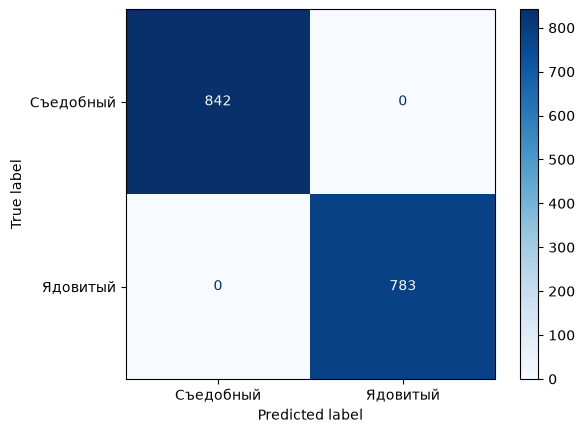

TN=842, FP=0, FN=0, TP=783


In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["Съедобный", "Ядовитый"],
    cmap="Blues", values_format="d"
)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

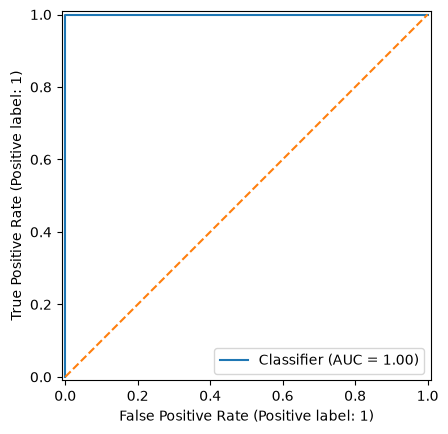

In [23]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "--")
plt.show()

ROC-AUC = 1, модель идеально разделяет съедобные и ядовитые грибы на тестовой выборке

In [24]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=5,
    random_state=42, n_jobs=2
)

importance_df = pd.Series(
    importance.importances_mean, index=X_test.columns
).sort_values(ascending=False)

importance_df.head(10).round(4)

odor                        0.1572
gill-size                   0.0562
gill-spacing                0.0206
stalk-root                  0.0174
stalk-surface-above-ring    0.0154
spore-print-color           0.0060
population                  0.0014
stalk-shape                 0.0013
gill-color                  0.0013
cap-color                   0.0009
dtype: float64

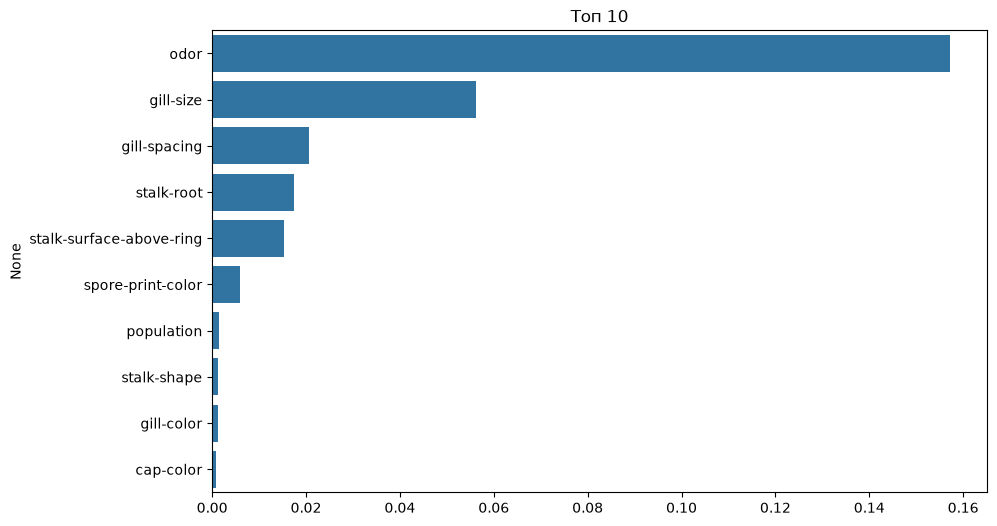

In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(x=importance_df.head(10).values, y=importance_df.head(10).index)
plt.title("Топ 10")
plt.show()

Гипотеза 6 подтвердилась